 # Phase 1 : exploration du jeu de candidats

 Prérequis : `python scripts/build_dataset.py` a produit `data/processed/candidates_v1.csv.gz`.

 Prototype de recherche : aucun diagnostic clinique.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]  # remonte de notebooks/phase_1 à la racine PaluScope
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.features.builder import FAMILIES, feature_columns

df = pd.read_csv(ROOT / "data/processed/candidates_v1.csv.gz")
train = df[df["split"] == "train"]
OUT = ROOT / "reports/phase_1"
OUT.mkdir(parents=True, exist_ok=True)

 ## 1. Taille, prévalence, candidats par image

In [2]:
print(df.groupby("split")["label"].agg(n_candidats="size", n_parasites="sum", prevalence="mean").round(3))
print("\ncandidats par image :\n", df.groupby("image_id").size().describe().round(1))
print("\nfeatures par famille :", {f: len(feature_columns(df, (f,))) for f in FAMILIES})


       n_candidats  n_parasites  prevalence
split                                      
test          3250         1257       0.387
train        15180         5954       0.392
val           3181         1329       0.418

candidats par image :
 count    1144.0
mean       18.9
std        12.9
min         1.0
25%         9.0
50%        17.0
75%        26.0
max        92.0
dtype: float64

features par famille : {'geo': 9, 'col': 70, 'grd': 3, 'tex': 14, 'hog': 324, 'qual': 5}


 ## 2. Pouvoir séparateur de chaque feature (AUC univariée, TRAIN uniquement)

 AUC = probabilité qu'un candidat « parasite » ait une valeur plus grande qu'un « non-parasite ».

 0,5 = aucune information ; loin de 0,5 (dans un sens ou l'autre) = informatif.

In [3]:
def auc(x: pd.Series, y: pd.Series) -> float:
    n1 = int(y.sum())
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = x.rank()
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


cols = [c for c in feature_columns(df, FAMILIES) if not c.startswith("hog_")]  # HOG : 324 colonnes, vues par ablation
scores = pd.Series({c: auc(train[c], train["label"]) for c in cols})
top = (scores - 0.5).abs().sort_values(ascending=False).index[:15]
print(scores[top].round(3))


col_b_std         0.774
col_g_std         0.773
col_gray_std      0.772
col_g_diff        0.228
col_gray_diff     0.230
col_v_diff        0.231
col_v_std         0.768
col_r_std         0.761
col_r_diff        0.245
col_s_std         0.741
col_b_diff        0.267
col_v_ratio       0.267
col_gray_ratio    0.277
geo_area          0.718
col_hsin_diff     0.283
dtype: float64


 ## 3. Variables de contexte `qual_` : indices d'un effet « image » (appareil, lame, éclairage)

 Une AUC éloignée de 0,5 sur une variable qui décrit l'image entière, pas le candidat,

 signale que l'étiquette dépend de l'image : à surveiller en Phase 2 et 3.

In [4]:
print(scores[[c for c in cols if c.startswith("qual_")]].round(3))


qual_sharpness              0.475
qual_brightness             0.501
qual_contrast               0.455
qual_overexposure_ratio     0.500
qual_underexposure_ratio    0.494
dtype: float64


 ## 4. Distributions des 6 features les plus séparatrices

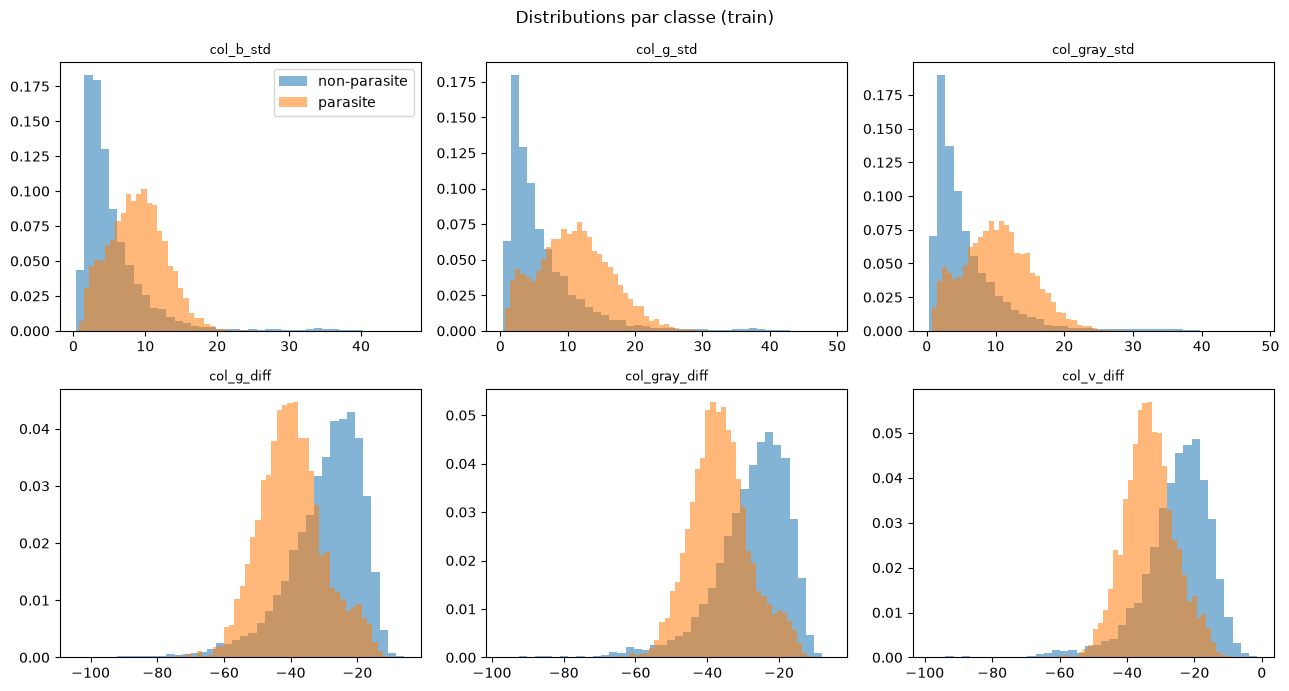

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), top[:6]):
    for lab, name in ((0, "non-parasite"), (1, "parasite")):
        ax.hist(train.loc[train["label"] == lab, c], bins=40, alpha=0.55, density=True, label=name)
    ax.set_title(c, fontsize=9)
axes[0, 0].legend()
fig.suptitle("Distributions par classe (train)")
fig.tight_layout()
fig.savefig(OUT / "features_top6_distributions.png", dpi=120)
plt.show()


 ## 5. Anomalies à noter dans la note de synthèse

 - nombre de features constantes ; valeurs aberrantes ; images sans candidat ; déséquilibre.

In [6]:
const = [c for c in feature_columns(df, FAMILIES) if train[c].nunique() <= 1]
print("features constantes sur le train :", const)
print("images sans aucun candidat (dans cette table) : voir reports/phase_1/candidate_recall.json")

features constantes sur le train : ['col_r_hist7', 'col_g_hist6', 'col_g_hist7', 'col_b_hist5', 'col_b_hist6', 'col_b_hist7', 'qual_overexposure_ratio']
images sans aucun candidat (dans cette table) : voir reports/phase_1/candidate_recall.json
